# 03 – Race analysis

In this notebook I answer the questions of the project one block at a time, using the cleaned laps from notebook 02. Each section loads a snapshot, calls functions of the package (`f1_telemetry.cleaning`, `f1_telemetry.analysis`, `f1_telemetry.visualization`) and shows the result. No analysis logic lives here.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

# The kernel may start in notebooks/ or in the project root: look upwards
# for pyproject.toml, which only exists in the root.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)

# Let Python find the package, which lives in src/ (no pip install needed)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

## Race and data

I choose the race with two constants. The data comes from the CSV snapshot, so the notebook runs without internet. Before anything else I check whether the race was wet: pace on a track that dries out or floods is not comparable lap by lap, so the pace analysis below only makes sense for a dry race.

In [3]:
from f1_telemetry.analysis import (
    compound_degradation,
    driver_pace,
    fuel_corrected_degradation,
    stint_degradation,
    strategy_summary,
)
from f1_telemetry.cleaning import (
    build_stints,
    get_clean_laps,
    is_wet_race,
    prepare_laps,
)
from f1_telemetry.data_loader import (
    LAP_DATETIME_COLUMNS,
    LAP_TIMEDELTA_COLUMNS,
    load_dataframe,
    snapshot_path,
)
from f1_telemetry.visualization import (
    plot_degradation_comparison,
    plot_pace_distribution,
    plot_stint_fit,
    plot_tyre_strategy,
)

YEAR = 2022
ROUND = 1
RACE_NAME = "Bahrain"

raw_laps = load_dataframe(
    snapshot_path(YEAR, ROUND, "R", "laps"),
    timedelta_columns=LAP_TIMEDELTA_COLUMNS,
    datetime_columns=LAP_DATETIME_COLUMNS,
)
laps = prepare_laps(raw_laps)
print(RACE_NAME, YEAR, "| laps:", len(laps), "| wet race:", is_wet_race(laps))

Bahrain 2022 | laps: 1125 | wet race: False


## B1 – Race pace

For each driver I take the median of the clean laps (no first lap, in or out lap, safety car or yellow flag, deleted lap). I use the median because a single odd lap hardly moves it. `CleanLaps` shows how many laps each number is based on, `StdTime` shows how consistent the driver was, and `GapToBest` is the distance in seconds from the driver with the fastest median. Drivers with fewer than 5 clean laps would be left out.

In [4]:
pace = driver_pace(laps)
pace.round(3)

,Driver,Team,CleanLaps,MedianTime,MeanTime,StdTime,FastestTime,GapToBest
0,LEC,Ferrari,46,97.693,97.599,1.295,94.570,0.000
1,PER,Red Bull Racing,42,98.058,98.061,1.278,96.089,0.365
2,VER,Red Bull Racing,41,98.091,97.847,1.177,95.440,0.398
3,SAI,Ferrari,44,98.150,98.018,1.285,95.740,0.457
4,HAM,Mercedes,42,98.380,98.303,1.182,96.228,0.688
5,RUS,Mercedes,44,98.822,98.627,1.195,96.302,1.129
6,TSU,AlphaTauri,42,99.040,99.354,1.248,97.104,1.347
7,MAG,Haas F1 Team,45,99.058,99.092,1.438,96.623,1.365
8,OCO,Alpine,43,99.188,99.290,1.176,97.110,1.495
9,GAS,AlphaTauri,39,99.513,99.528,1.018,97.324,1.820


The boxplot shows all clean laps of each driver, with the fastest median on the left. A tall box means the lap times varied during the race. That variation mixes real inconsistency with tyre compound, tyre wear and fuel burn, so I do not read it as "consistency" alone; the degradation block looks at those effects separately.

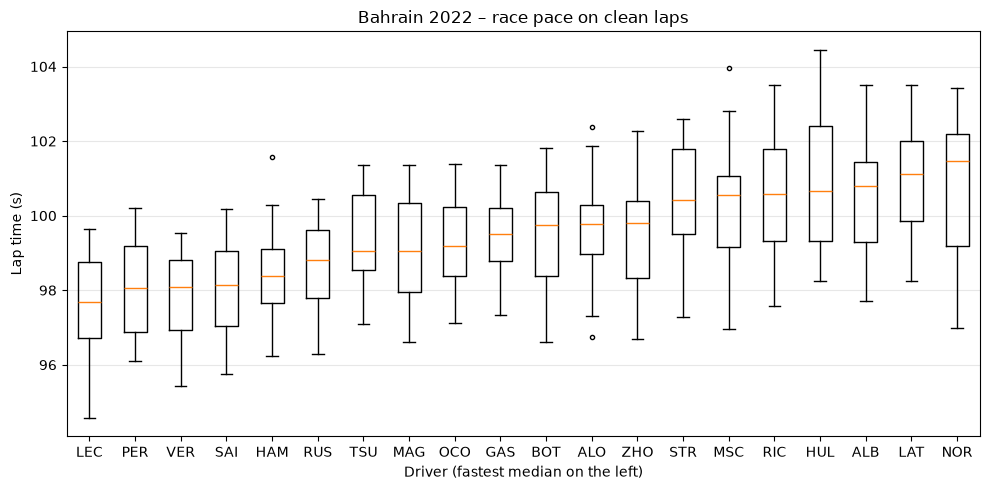

In [5]:
clean = get_clean_laps(laps)
fig = plot_pace_distribution(
    clean, pace, title=f"{RACE_NAME} {YEAR} – race pace on clean laps"
)

Race pace is not the finishing order. As a quick look, I put the pace rank next to the grid and finishing positions from the results snapshot. Differences can come from the grid, strategy, safety cars or retirements; the next blocks and the grid-versus-finish analysis look at those.

In [6]:
results = load_dataframe(snapshot_path(YEAR, ROUND, "R", "results"))
compare = (
    pace[["Driver", "Team", "MedianTime"]]
    .merge(
        results[["Abbreviation", "GridPosition", "Position"]],
        left_on="Driver",
        right_on="Abbreviation",
        how="left",
    )
    .drop(columns="Abbreviation")
)
compare.insert(0, "PaceRank", compare.index + 1)
compare.round(3)

,PaceRank,Driver,Team,MedianTime,GridPosition,Position
0,1,LEC,Ferrari,97.693,1.0,1.0
1,2,PER,Red Bull Racing,98.058,4.0,18.0
2,3,VER,Red Bull Racing,98.091,2.0,19.0
3,4,SAI,Ferrari,98.150,3.0,2.0
4,5,HAM,Mercedes,98.380,5.0,3.0
5,6,RUS,Mercedes,98.822,9.0,4.0
6,7,TSU,AlphaTauri,99.040,16.0,8.0
7,8,MAG,Haas F1 Team,99.058,7.0,5.0
8,9,OCO,Alpine,99.188,11.0,7.0
9,10,GAS,AlphaTauri,99.513,10.0,20.0


**What I see (Bahrain 2022).** Leclerc has the fastest median (97.693 s). The next three, Pérez, Verstappen and Sainz, are within half a second of him, so the front of the field was close. The Mercedes are about 0.7 s (Hamilton) and 1.1 s (Russell) behind, and the slowest median (Norris) is 3.77 s off. Pace rank is not the finishing order: Pérez and Verstappen are second and third on pace but finished 18th and 19th, and Gasly is tenth on pace but finished last, all because they retired. Tsunoda shows the opposite case: seventh on pace, started 16th, finished 8th.

Check: the clean-lap filter must not remove the fastest lap of the race.

In [7]:
print("Fastest lap, all laps:", laps["LapTimeSeconds"].min())
print("Fastest lap, clean laps:", clean["LapTimeSeconds"].min())

Fastest lap, all laps: 94.57
Fastest lap, clean laps: 94.57


## B2 – Tyre strategy

A stint is the time a driver spends on one set of tyres. `build_stints` gives one row per driver and stint, using all laps (a stint includes its in and out laps). From it, `strategy_summary` writes each driver's strategy as the order of compounds and counts the stops. `Stops` counts every tyre change. I show the table in finishing order, taken from the results snapshot, so the winner is on top.

In [8]:
order = results.sort_values("Position")["Abbreviation"].tolist()
stints = build_stints(laps)
strategy = strategy_summary(stints).set_index("Driver").loc[order].reset_index()
strategy

,Driver,Stops,Strategy,Laps
0,LEC,3,SOFT > SOFT > MEDIUM > SOFT,57
1,SAI,3,SOFT > SOFT > MEDIUM > SOFT,57
2,HAM,3,SOFT > HARD > MEDIUM > SOFT,57
3,RUS,3,SOFT > HARD > MEDIUM > SOFT,57
4,MAG,3,SOFT > SOFT > MEDIUM > SOFT,57
5,BOT,3,SOFT > MEDIUM > MEDIUM > SOFT,57
6,OCO,3,SOFT > MEDIUM > HARD > SOFT,57
7,TSU,3,SOFT > MEDIUM > SOFT > SOFT,57
8,ALO,3,SOFT > MEDIUM > HARD > SOFT,57
9,ZHO,3,SOFT > MEDIUM > MEDIUM > SOFT,57


Two quick counts: how many stops the drivers made, and which strategies were used most.

In [9]:
print(strategy["Stops"].value_counts().sort_index())
print()
print(strategy["Strategy"].value_counts())

Stops
2     2
3    18
Name: count, dtype: int64

Strategy
SOFT > SOFT > MEDIUM > SOFT      7
SOFT > MEDIUM > MEDIUM > SOFT    3
SOFT > HARD > MEDIUM > SOFT      2
SOFT > MEDIUM > HARD > SOFT      2
SOFT > MEDIUM > SOFT > SOFT      2
SOFT > MEDIUM > SOFT             1
MEDIUM > SOFT > HARD > SOFT      1
MEDIUM > HARD > SOFT > SOFT      1
SOFT > MEDIUM > HARD             1
Name: count, dtype: int64


Each row of the chart is one driver, in finishing order; each segment is a stint, placed at its real laps and coloured by compound (S soft, M medium, H hard). A row that ends early is a retirement. A driver who stops on the track in a late lap, like Pérez, still shows that lap, because the table has a row for it (the 57 against 56 laps I found in notebook 01).

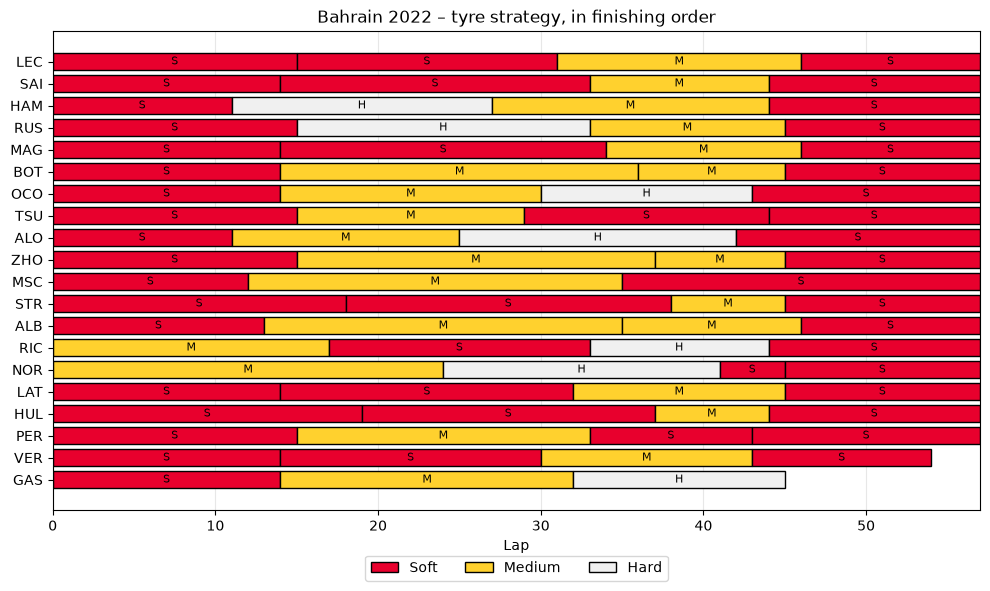

In [10]:
fig = plot_tyre_strategy(
    stints, order, title=f"{RACE_NAME} {YEAR} – tyre strategy, in finishing order"
)

**What I see (Bahrain 2022).** Three stops was the norm: 18 of the 20 drivers changed tyres three times. Only Schumacher made two, and Gasly made two before retiring on lap 45. Almost everyone started on softs (only Ricciardo and Norris started on mediums), and the most common strategy, used by seven drivers including Leclerc and Sainz, was soft–soft–medium–soft. Everyone still running at the end finished on softs, and hard tyres were used by only seven drivers. First stops cluster between laps 11 and 19 and the last ones between laps 42 and 46; I want to compare these with the safety-car laps, because a stop under a safety car costs less time.

## B3 – Tyre degradation

Degradation is how much slower a lap gets for each extra lap of tyre age. First the simple way: inside each stint I fit a straight line of lap time against tyre age, using clean laps only, and the slope is the degradation in seconds per lap. Stints with fewer than 8 clean laps are left out because their line would be mostly noise. This only makes sense in a dry race, which Bahrain is.

In [11]:
fits = stint_degradation(laps)
print("Stints fitted:", len(fits), "of", len(stints))
fits.round(3)

Stints fitted: 54 of 78


,Driver,Stint,Compound,Laps,Slope,Intercept,RSquared,StdErr
0,ALB,1,SOFT,11,0.233,100.343,0.659,0.056
1,ALB,2,MEDIUM,20,0.072,100.058,0.515,0.016
2,ALO,1,SOFT,9,0.240,98.768,0.694,0.060
3,ALO,2,MEDIUM,11,0.066,99.458,0.238,0.039
4,ALO,3,HARD,14,0.136,98.104,0.831,0.018
5,BOT,1,SOFT,12,0.006,101.033,0.004,0.032
6,BOT,2,MEDIUM,20,0.019,99.478,0.052,0.019
7,GAS,1,SOFT,12,0.126,99.319,0.951,0.009
8,GAS,2,MEDIUM,16,0.095,98.530,0.754,0.014
9,GAS,3,HARD,11,0.032,98.235,0.021,0.074


One slope per stint is a lot of numbers. For each compound I summarise them: the median slope is the main number because one noisy stint hardly moves it, and the minimum and maximum show how different the stints were.

In [12]:
naive = compound_degradation(fits)
naive.round(3)

,Compound,Stints,MedianSlope,MeanSlope,MinSlope,MaxSlope
0,SOFT,29,0.126,0.134,0.006,0.286
1,MEDIUM,18,0.086,0.084,0.019,0.170
2,HARD,7,0.068,0.079,0.032,0.136


To see what the method does, I draw two stints. Magnussen's second stint (18 clean laps, R² 0.99) shows a clear straight trend: the lap time rises with tyre age. Norris's first stint has even more clean laps (20) but the dots scatter (R² 0.13), so its slope is very uncertain. Single stints can be very noisy, which is why I summarise over many stints and fit one model to all of them.

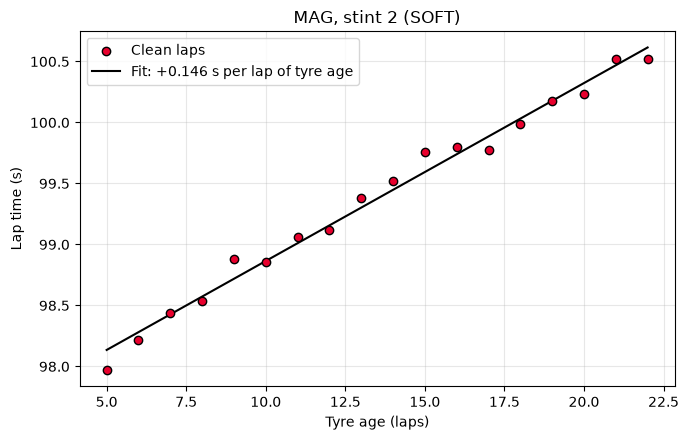

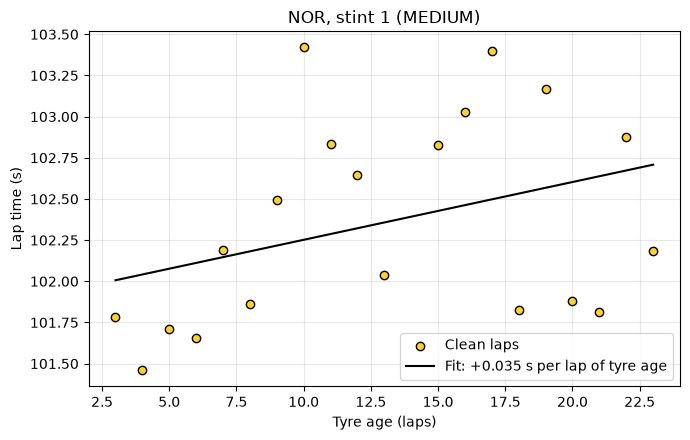

In [17]:
fig_clear = plot_stint_fit(clean, fits, "MAG", 2)
fig_noisy = plot_stint_fit(clean, fits, "NOR", 1)

The simple fit has a problem: the car burns fuel and gets lighter, so it also gets faster lap after lap, which hides part of the tyre wear. The fuel-corrected model fits all clean laps at once: each driver has a base pace, each compound an offset and a tyre-age slope, and there is one extra term for the race lap number (fuel burn plus the track getting rubbered in; the data cannot tell the two apart). Tyre age restarts at each stop but lap number does not, which is what lets the model separate the two effects. In the table, each compound row is the corrected degradation and the `LapNumber` row is the change in lap time per race lap at the same tyre age.

In [14]:
model = fuel_corrected_degradation(laps)
model.round(4)

,Term,Slope,StdErr,Laps
0,SOFT,0.1795,0.0066,478
1,MEDIUM,0.1467,0.0065,287
2,HARD,0.1575,0.0144,89
3,LapNumber,-0.0846,0.0013,854


In [15]:
lap_effect = model.set_index("Term").loc["LapNumber"]
race_laps = int(laps["LapNumber"].max())
total_change = lap_effect["Slope"] * (race_laps - 1)
print(
    f"Lap number term: {lap_effect['Slope']:.4f} s per lap "
    f"(plus or minus {2 * lap_effect['StdErr']:.4f})"
)
print(f"Over {race_laps - 1} laps that adds up to {total_change:.2f} s")

Lap number term: -0.0846 s per lap (plus or minus 0.0027)
Over 56 laps that adds up to -4.74 s


Now the two estimates side by side. The bars on the left of each pair are the simple slopes (median over stints); the bars on the right are the fuel-corrected slopes, with an error bar of two standard errors. If the correction matters, the right bar differs clearly from the left one.

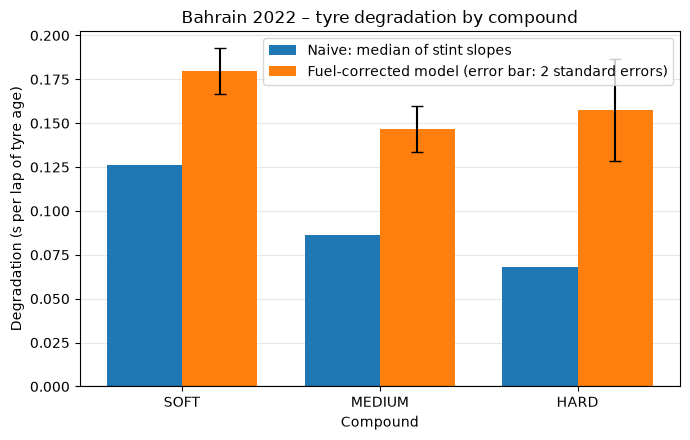

In [16]:
fig = plot_degradation_comparison(
    naive, model, title=f"{RACE_NAME} {YEAR} – tyre degradation by compound"
)

**What I see (Bahrain 2022).** Fitting each stint separately gives a median degradation of 0.126 s per lap for softs, 0.086 for mediums and 0.068 for hards, so hards look much kinder to the tyres. But a stint's slope also contains the effect of the car getting lighter. The fuel-corrected model estimates that effect from all laps together: about −0.085 s per race lap (−4.7 s over the race), which also contains the track improving, so it is an upper bound for fuel alone. With it removed the degradation is 0.180 s per lap for softs, 0.147 for mediums and 0.158 for hards. Softs wear faster than mediums, but medium and hard cannot be told apart: the hard estimate rests on only 89 laps and 7 stints, and its error bar covers the medium value. The error bars assume independent laps, so they are probably too narrow.